In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
RESULTS = ROOT / "evaluation" / "results"
LT = RESULTS / "listening_test"
sys.path.insert(0, str(ROOT / "evaluation"))
from analyze_listening_test import nmos_rows, turing_rows  # noqa: E402

plt.rcParams["figure.dpi"] = 110
MODEL_ORDER = ["qwen3", "s2pro", "voxtral"]
MODEL_LABELS = {"qwen3": "Qwen3", "s2pro": "S2 Pro", "voxtral": "Voxtral", "REAL": "Genuine"}
COLORS = {"qwen3": "#4c72b0", "s2pro": "#dd8452", "voxtral": "#55a868", "REAL": "#8c8c8c"}

In [2]:
obj_summary = pd.read_csv(RESULTS / "objective_summary.csv")
obj_pairwise = pd.read_csv(RESULTS / "objective_pairwise.csv")
nmos_summary = pd.read_csv(LT / "nmos_summary.csv")
nmos_pairwise = pd.read_csv(LT / "nmos_pairwise.csv")
turing_summary = pd.read_csv(LT / "turing_summary.csv")
turing_familiarity = pd.read_csv(LT / "turing_familiarity.csv")
reliability = pd.read_csv(LT / "reliability.csv").iloc[0]
ratings_long = pd.read_csv(LT / "ratings_long.csv")

nmos_summary["order"] = nmos_summary["condition"].map(lambda c: MODEL_ORDER.index(c) if c in MODEL_ORDER else 99)
nmos_summary = nmos_summary.sort_values("order")
nmos_summary.head(10)

,condition,is_reference,is_anchor,mean,ci_low,ci_high,sd_of_answers,n_answers,n_raters,n_items,order
0,qwen3,False,False,3.041,2.710,3.374,1.222,197,30,13,0
1,s2pro,False,False,3.924,3.636,4.216,0.987,197,30,13,1
2,voxtral,False,False,4.055,3.788,4.336,1.016,197,30,13,2
3,REAL,True,False,4.156,3.805,4.459,0.956,196,30,13,99


## 1 - Objective metrics

Speaker similarity (WavLM cosine, higher is better) and word error rate come with genuine
recordings as a reference point; real-time factor and time-to-first-audio don't apply to a
human voice, so those two only cover the three services.

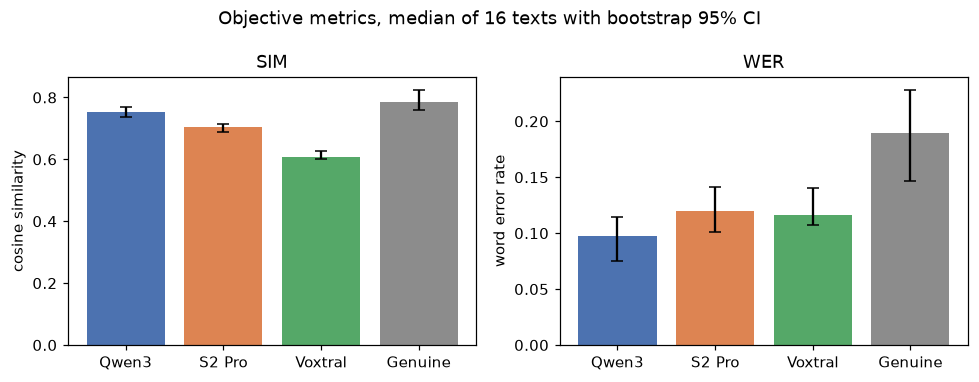

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, metric, ylabel in zip(axes, ["sim", "wer"], ["cosine similarity", "word error rate"]):
    sub = obj_summary[obj_summary["metric"] == metric]
    sub = sub.set_index("model").reindex(MODEL_ORDER + ["REAL"]).dropna(how="all")
    yerr = [sub["median"] - sub["ci_low"], sub["ci_high"] - sub["median"]]
    ax.bar(sub.index.map(lambda m: MODEL_LABELS[m]), sub["median"],
           yerr=yerr, capsize=4, color=[COLORS[m] for m in sub.index])
    ax.set_ylabel(ylabel)
    ax.set_title(metric.upper())
fig.suptitle("Objective metrics, median of 16 texts with bootstrap 95% CI")
fig.tight_layout()

REAL's WER (0.19) is higher than any of the three clones. That is not a synthesis
failing - it's Whisper struggling with a distance-mic voice message against a script Whisper
itself produced from a *clean* zero-shot render. WER here says more about how forgiving the
input audio is to transcribe than about intelligibility, which is worth a line in the
limitations section.

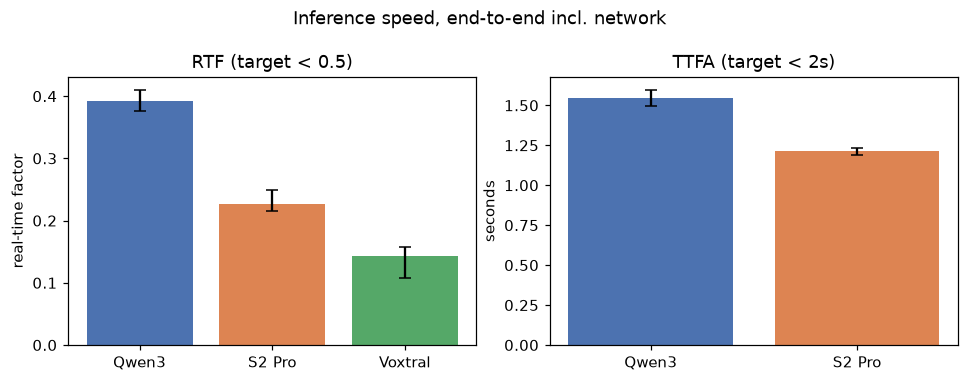

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, metric, ylabel in zip(axes, ["service_rtf", "ttfa_s"], ["real-time factor", "seconds"]):
    sub = obj_summary[obj_summary["metric"] == metric]
    sub = sub.set_index("model").reindex(MODEL_ORDER).dropna(how="all")
    yerr = [sub["median"] - sub["ci_low"], sub["ci_high"] - sub["median"]]
    ax.bar(sub.index.map(lambda m: MODEL_LABELS[m]), sub["median"],
           yerr=yerr, capsize=4, color=[COLORS[m] for m in sub.index])
    ax.set_ylabel(ylabel)
    ax.set_title("RTF (target < 0.5)" if metric == "service_rtf" else "TTFA (target < 2s)")
fig.suptitle("Inference speed, end-to-end incl. network")
fig.tight_layout()

No TTFA bar for Voxtral - the run never logged a streaming first-chunk timestamp for
it, so the field is empty rather than zero. Worth fixing in the harness before the next
round, not worth guessing at here.

## 2 - Naturalness (N-MOS)

30 raters, ACR 1-5 scale, genuine recordings mixed in unlabeled as the upper anchor. Dots are
each rater's own mean for that condition, so the bar isn't hiding how much people actually
agree.

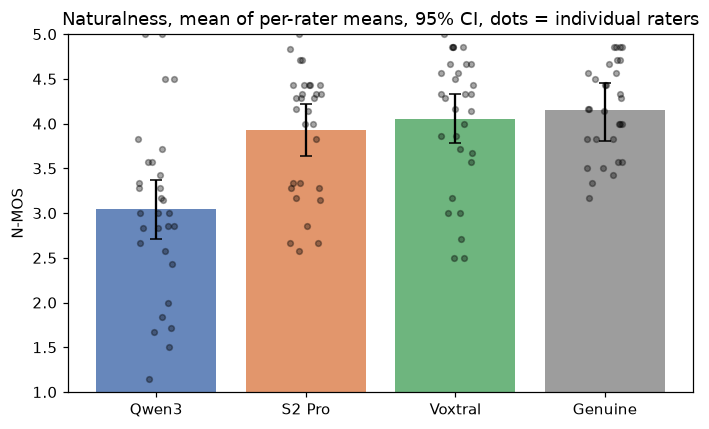

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4))
conditions = nmos_summary["condition"].tolist()
x = np.arange(len(conditions))

nmos_all = ratings_long[ratings_long["part"] == "nmos"]
per_rater = (nmos_all[nmos_all["repeat"] == False]
             .groupby(["condition", "rater"])["rating"].mean().reset_index())

rng = np.random.default_rng(0)
for i, cond in enumerate(conditions):
    vals = per_rater.loc[per_rater["condition"] == cond, "rating"]
    ax.scatter(np.full(len(vals), i) + rng.uniform(-0.12, 0.12, len(vals)), vals,
               color="black", alpha=0.35, s=14, zorder=3)

row = nmos_summary.set_index("condition")
yerr = [row.loc[conditions, "mean"] - row.loc[conditions, "ci_low"],
        row.loc[conditions, "ci_high"] - row.loc[conditions, "mean"]]
ax.bar(x, row.loc[conditions, "mean"], yerr=yerr, capsize=4, alpha=0.85,
       color=[COLORS[c] for c in conditions])
ax.set_xticks(x)
ax.set_xticklabels([MODEL_LABELS[c] for c in conditions])
ax.set_ylabel("N-MOS")
ax.set_ylim(1, 5)
ax.set_title("Naturalness, mean of per-rater means, 95% CI, dots = individual raters")
fig.tight_layout()

In [6]:
nmos_pairwise[["condition_a", "condition_b", "difference", "ci_low", "ci_high", "excludes_zero_adj"]]

,condition_a,condition_b,difference,ci_low,ci_high,excludes_zero_adj
0,qwen3,s2pro,-0.883,-1.165,-0.593,True
1,qwen3,voxtral,-1.013,-1.374,-0.662,True
2,qwen3,REAL,-1.115,-1.499,-0.681,True
3,s2pro,voxtral,-0.131,-0.413,0.145,False
4,s2pro,REAL,-0.233,-0.618,0.187,False
5,voxtral,REAL,-0.102,-0.476,0.302,False


Qwen3 sits clearly below the other three, even after the Bonferroni correction for six
pairwise comparisons. S2 Pro, Voxtral and the genuine recordings are statistically
indistinguishable from each other - none of those three pairwise intervals excludes zero.

## 3 - Objective similarity vs. perceived naturalness

Same four conditions, SIM on one axis and N-MOS on the other. If the objective baseline
tracked human perception, this would be roughly monotonic.

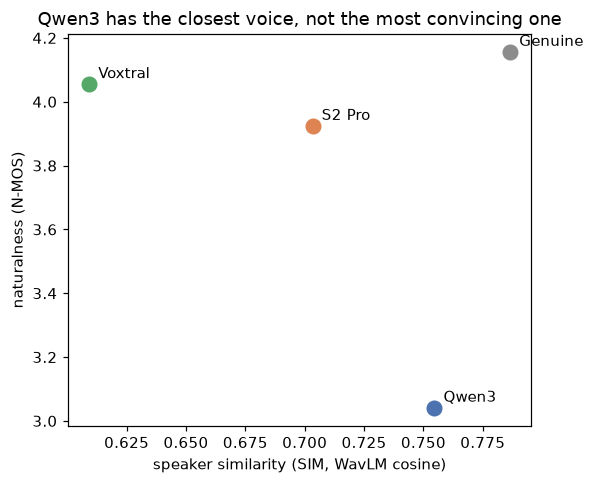

In [7]:
sim_by_model = obj_summary[obj_summary["metric"] == "sim"].set_index("model")["median"]
nmos_by_model = nmos_summary.set_index("condition")["mean"]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for cond in ["qwen3", "s2pro", "voxtral", "REAL"]:
    ax.scatter(sim_by_model[cond], nmos_by_model[cond], s=90, color=COLORS[cond], zorder=3)
    ax.annotate(MODEL_LABELS[cond], (sim_by_model[cond], nmos_by_model[cond]),
                xytext=(6, 4), textcoords="offset points")
ax.set_xlabel("speaker similarity (SIM, WavLM cosine)")
ax.set_ylabel("naturalness (N-MOS)")
ax.set_title("Qwen3 has the closest voice, not the most convincing one")
fig.tight_layout()

Qwen3 has the highest SIM of the three clones - closest to the patient's voice by the
embedding - and the lowest N-MOS and (see below) the lowest Turing fooling rate. Voxtral is
the reverse: worst SIM, best naturalness, hardest to catch. A cosine similarity between
speaker embeddings is not a proxy for "sounds like a real person," and this dataset makes
that gap visible instead of theoretical. Worth a paragraph in the discussion, not just a
footnote.

## 4 - Voice Turing test

Share of answers where the rater picked the clone over the genuine recording. 0.50 is chance
- the best possible outcome here, since it means the clone was indistinguishable.

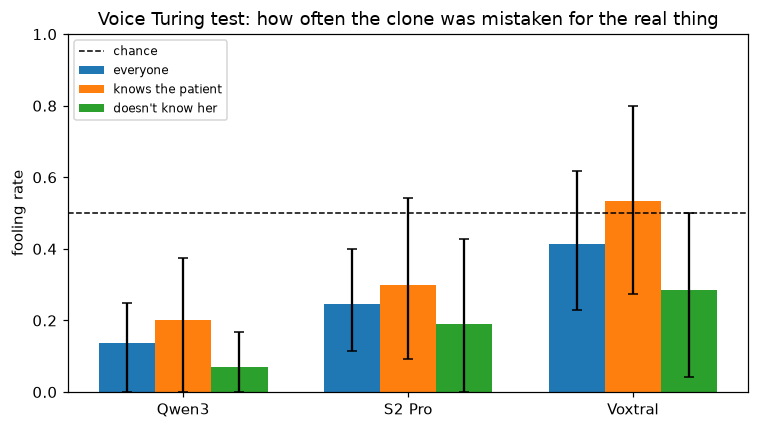

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
groups = ["all", "knows_person", "does_not_know_person"]
group_labels = {"all": "everyone", "knows_person": "knows the patient",
                "does_not_know_person": "doesn't know her"}
width = 0.25
x = np.arange(len(MODEL_ORDER))

for i, group in enumerate(groups):
    sub = turing_summary[turing_summary["group"] == group].set_index("model").reindex(MODEL_ORDER)
    yerr = [sub["fooling_rate"] - sub["ci_low"], sub["ci_high"] - sub["fooling_rate"]]
    ax.bar(x + (i - 1) * width, sub["fooling_rate"], width, yerr=yerr, capsize=3,
           label=group_labels[group])

ax.axhline(0.5, color="black", linestyle="--", linewidth=1, label="chance")
ax.set_xticks(x)
ax.set_xticklabels([MODEL_LABELS[m] for m in MODEL_ORDER])
ax.set_ylabel("fooling rate")
ax.set_ylim(0, 1)
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Voice Turing test: how often the clone was mistaken for the real thing")
fig.tight_layout()

Same ranking as N-MOS: Qwen3 is caught most reliably, Voxtral is the only one whose CI
touches chance level for either group. Raters who know the patient are fooled *more* often
than strangers for all three models (`turing_familiarity.csv`), which runs against the
intuition that familiarity should make forgeries easier to spot - but every one of those
three confidence intervals still includes zero, so at n=30 this is a trend to flag, not a
result to lean on.

## 5 - The one rater who actually knows the real thing

`one_rating.jsonl` holds a single session: the patient herself, rating clones of her own
voice. She is deliberately kept out of the panel above - one person can't contribute a
between-rater interval, and pooling her in would quietly weight the average by someone whose
judgement is not exchangeable with a stranger's. Set side by side instead.

In [9]:
with open(LT / "key.json", encoding="utf-8") as f:
    key = json.load(f)
with open(LT / "responses" / "one_rating.jsonl", encoding="utf-8") as f:
    patient_response = json.loads(f.read())

patient_nmos = pd.DataFrame(nmos_rows(key, [patient_response]))
patient_turing = pd.DataFrame(turing_rows(key, [patient_response]))
patient_nmos = patient_nmos[~patient_nmos["repeat"]]

patient_means = patient_nmos.groupby("condition")["rating"].mean()
patient_means

condition
REAL       4.714286
qwen3      2.285714
s2pro      3.857143
voxtral    4.142857
Name: rating, dtype: float64

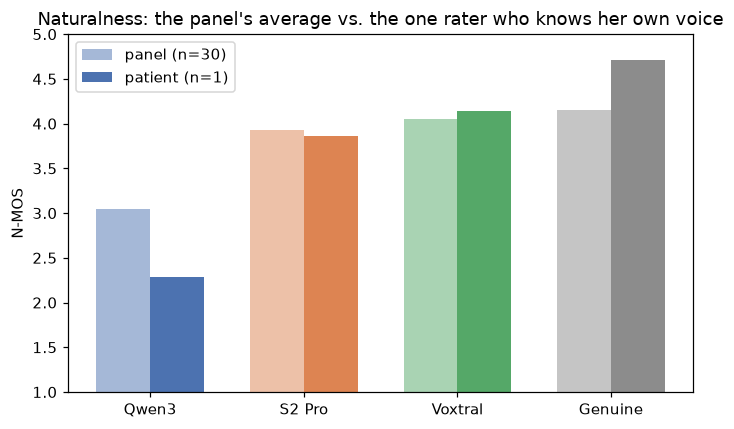

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 4))
conditions = [c for c in ["qwen3", "s2pro", "voxtral", "REAL"] if c in patient_means.index]
x = np.arange(len(conditions))
width = 0.35

ax.bar(x - width / 2, nmos_by_model[conditions], width, label="panel (n=30)",
       color=[COLORS[c] for c in conditions], alpha=0.5)
ax.bar(x + width / 2, patient_means[conditions], width, label="patient (n=1)",
       color=[COLORS[c] for c in conditions])
ax.set_xticks(x)
ax.set_xticklabels([MODEL_LABELS[c] for c in conditions])
ax.set_ylabel("N-MOS")
ax.set_ylim(1, 5)
ax.legend()
ax.set_title("Naturalness: the panel's average vs. the one rater who knows her own voice")
fig.tight_layout()

She rates Qwen3 half a point below the panel average and her own genuine recordings
half a point above it - a harsher and a more generous judgement at the same time, in exactly
the directions you'd expect from someone who has a ground truth to compare against instead of
guessing. S2 Pro and Voxtral land close to the panel mean.

The bigger result is the Turing test: she was not fooled once, in either direction, across
all six pairs she saw.

In [11]:
patient_turing[["model", "text_id", "correct", "fooled"]]

,model,text_id,correct,fooled
0,qwen3,AUDIO-2021-08-16-08-21-22,True,False
1,s2pro,AUDIO-2021-08-27-06-40-12,True,False
2,voxtral,AUDIO-2021-07-30-06-44-26,True,False
3,s2pro,AUDIO-2021-08-31-06-43-34,True,False
4,voxtral,AUDIO-2021-08-26-07-23-40,True,False
5,qwen3,AUDIO-2021-08-28-15-31-46,True,False


6 pairs is an anecdote, not a rate - no CI is reported for n=1. But it's a clean
anecdote: the panel's fooling rate for the same three models sits between 0.14 and 0.41, and
the only rater with a real reference for what the patient's voice actually sounds like scored
0/6. It illustrates why "sounds like a person" and "sounds like *this* person" are
different questions, and why the panel's familiarity split in Section 4 should be read as a
hint, not a conclusion - a single well-informed rater moved in the opposite direction from
the trend. How much weight 0/6 can carry is checked pair by pair in 5b.

### 5b - Clip by clip, against the same panel raters

The comparison above is at condition level. It can be sharper: the patient's plan (id 5)
drew from the same stimulus pool as the panel, so every one of her 28 scored clips was also
rated by 16-17 panel raters, and every one of her six Turing pairs by 7 panel raters. That
makes a clip-level and pair-level comparison possible without any text-difficulty confound -
she and the panel heard identical audio.

mean |patient - panel| per clip: 0.61 points


,mean,min,max,count
condition,,,,
REAL,0.40,-0.65,0.88,7
qwen3,-0.69,-2.18,0.12,7
s2pro,-0.13,-1.47,0.82,7
voxtral,-0.04,-1.53,0.59,7


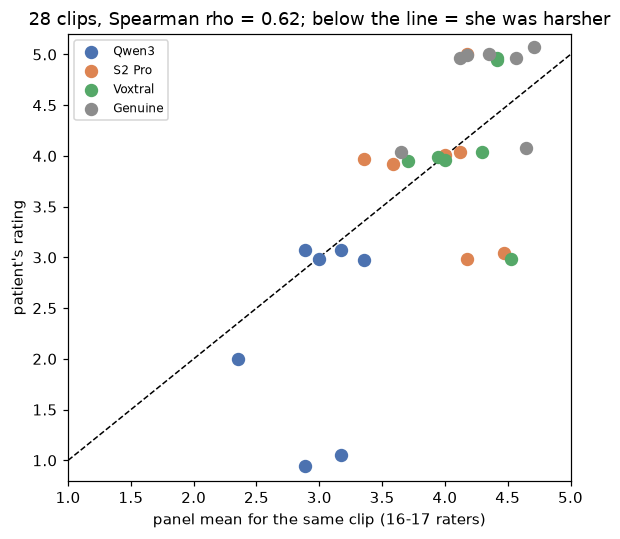

In [12]:
panel_by_clip = (ratings_long[(ratings_long["part"] == "nmos") & (ratings_long["repeat"] == False)]
                 .groupby("stimulus")["rating"].agg(panel_mean="mean", n_raters="nunique"))
clip = patient_nmos.merge(panel_by_clip, on="stimulus")
clip["diff"] = clip["rating"] - clip["panel_mean"]

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([1, 5], [1, 5], color="black", linestyle="--", linewidth=1)
rng = np.random.default_rng(1)
for cond in ["qwen3", "s2pro", "voxtral", "REAL"]:
    sub = clip[clip["condition"] == cond]
    ax.scatter(sub["panel_mean"], sub["rating"] + rng.uniform(-0.08, 0.08, len(sub)),
               color=COLORS[cond], s=60, label=MODEL_LABELS[cond], zorder=3)
ax.set_xlim(1, 5)
ax.set_ylim(0.8, 5.2)
ax.set_xlabel("panel mean for the same clip (16-17 raters)")
ax.set_ylabel("patient's rating")
rho = clip["rating"].corr(clip["panel_mean"], method="spearman")
ax.set_title(f"{len(clip)} clips, Spearman rho = {rho:.2f}; below the line = she was harsher")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()

print(f"mean |patient - panel| per clip: {clip['diff'].abs().mean():.2f} points")
clip.groupby("condition")["diff"].agg(["mean", "min", "max", "count"]).round(2)

She and the panel largely agree on *which* clips are good: rank correlation 0.62 across 28
clips, and her typical distance from the panel mean (0.61 points) is about the panel's own
repeat noise floor from Section 6 (0.55). The disagreement is concentrated, not diffuse. Two
Qwen3 clips she scored 1 where the panel sat around 3 (`s_015`, `s_003`), and three S2 Pro /
Voxtral clips she scored 3 where the panel gave 4.2-4.5 (`s_041`, `s_038`, `s_008`). Everything
else is within a point. So the half-point Qwen3 gap in the bar chart above is driven by two
clips she found unacceptable, not by a uniformly lower opinion of the model.

Her own two hidden repeats (`s_016`, `s_048`) each differed by exactly one point, so she is
no more consistent than the panel - the outliers above are not a sign of a steadier rater.

,panel_gap,patient_gap
condition,,
qwen3,-1.34,-2.43
s2pro,-0.33,-0.86
voxtral,-0.13,-0.57


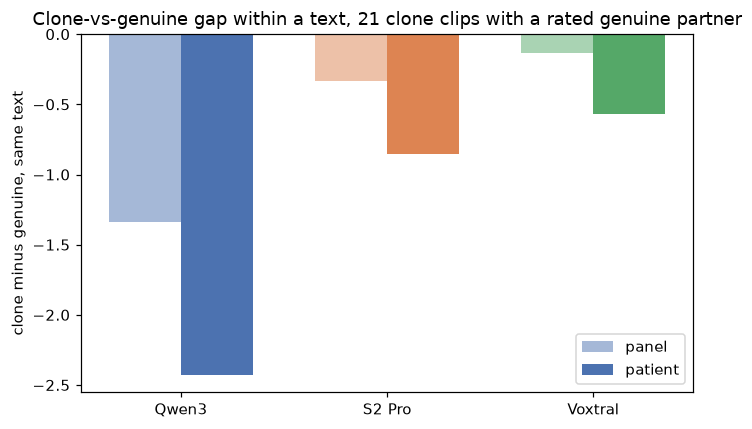

In [13]:
real_pat = clip[clip["condition"] == "REAL"].set_index("text_id")["rating"]
real_panel = clip[clip["condition"] == "REAL"].set_index("text_id")["panel_mean"]
gaps = clip[clip["condition"] != "REAL"].copy()
gaps["patient_gap"] = gaps["rating"] - gaps["text_id"].map(real_pat)
gaps["panel_gap"] = gaps["panel_mean"] - gaps["text_id"].map(real_panel)
gaps = gaps.dropna(subset=["patient_gap"])
gap_means = gaps.groupby("condition")[["panel_gap", "patient_gap"]].mean().reindex(MODEL_ORDER)

fig, ax = plt.subplots(figsize=(6.5, 4))
x = np.arange(len(MODEL_ORDER))
width = 0.35
ax.bar(x - width / 2, gap_means["panel_gap"], width, label="panel",
       color=[COLORS[m] for m in MODEL_ORDER], alpha=0.5)
ax.bar(x + width / 2, gap_means["patient_gap"], width, label="patient",
       color=[COLORS[m] for m in MODEL_ORDER])
ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels([MODEL_LABELS[m] for m in MODEL_ORDER])
ax.set_ylabel("clone minus genuine, same text")
ax.set_title(f"Clone-vs-genuine gap within a text, {len(gaps)} clone clips with a rated genuine partner")
ax.legend()
fig.tight_layout()
gap_means.round(2)

This is the cleanest view of what knowing the voice does. For each of the 7 texts where she
rated both the genuine recording and its clones, the clone-minus-genuine gap is roughly twice
the panel's for every model: Qwen3 -2.4 vs -1.3, S2 Pro -0.9 vs -0.3, Voxtral -0.6 vs -0.1.
The panel hears S2 Pro and Voxtral as essentially indistinguishable from the genuine
recordings (Section 2); she does not, even though her absolute scores for those two models
match the panel's. The extra distance comes from the top end - she rates her own recordings
higher than strangers do - which is exactly the pattern of a rater who is scoring "is this
me" on top of "is this natural".

In [14]:
panel_turing = ratings_long[ratings_long["part"] == "turing"].copy()
panel_turing["correct"] = panel_turing["correct"].astype(bool)
knows = panel_turing["knows_person"] == "yes"
same_pairs = (panel_turing[panel_turing["pair_id"].isin(patient_turing["pair_id"])]
              .groupby(["pair_id", "model", "text_id"])
              .agg(panel_raters=("rater", "nunique"),
                   panel_correct=("correct", "mean"),
                   knows_her_correct=("correct", lambda s: s[knows.loc[s.index]].mean()))
              .reset_index()
              .merge(patient_turing[["pair_id", "correct"]].rename(columns={"correct": "patient_correct"}),
                     on="pair_id"))

per_rater_acc = panel_turing.groupby("rater")["correct"].mean()
print(f"panel on these six pairs: {same_pairs['panel_correct'].mean():.0%} correct")
print(f"{(per_rater_acc == 1).sum()} of {len(per_rater_acc)} panel raters also made no mistake on their own pairs")
same_pairs.round(2)

panel on these six pairs: 69% correct
6 of 29 panel raters also made no mistake on their own pairs


,pair_id,model,text_id,panel_raters,panel_correct,knows_her_correct,patient_correct
0,q_034,qwen3,AUDIO-2021-08-16-08-21-22,7,0.71,0.75,True
1,q_035,voxtral,AUDIO-2021-08-26-07-23-40,7,0.43,0.25,True
2,q_036,s2pro,AUDIO-2021-08-27-06-40-12,7,1.00,1.00,True
3,q_037,qwen3,AUDIO-2021-08-28-15-31-46,7,0.71,0.75,True
4,q_038,voxtral,AUDIO-2021-07-30-06-44-26,7,0.43,0.25,True
5,q_039,s2pro,AUDIO-2021-08-31-06-43-34,7,0.86,1.00,True


Put next to the panel on the identical six pairs, 0/6 fooled is less singular than it
sounds. The panel got 69% of these answers right, and 6 of 29 panel raters also made no
mistake on the pairs they saw - so a perfect sheet is something one in five strangers
managed too, and at a 69% per-answer rate the chance of six in a row is about 11%. What
does stand out is *where* she was right: the two Voxtral pairs (`q_035`, `q_038`) are the
only ones where the panel was below chance, and the panel raters who know her got just 1 in 4
of those answers right. She got both. That, not the clean sweep itself, is the part worth a
sentence in the report.

## 6 - Rating noise, for scale

Two stimuli were repeated to each rater without telling them. The spread between a rater's
two scores for the identical audio is the noise floor against which every difference above
should be read.

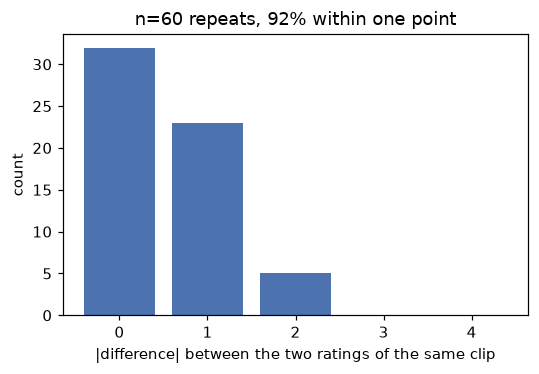

In [15]:
nmos_rows_all = ratings_long[ratings_long["part"] == "nmos"]
deltas = (nmos_rows_all.groupby(["rater", "stimulus"])["rating"]
          .agg(lambda s: s.max() - s.min() if len(s) > 1 else np.nan)
          .dropna())

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.hist(deltas, bins=range(0, 6), align="left", rwidth=0.8, color="#4c72b0")
ax.set_xlabel("|difference| between the two ratings of the same clip")
ax.set_ylabel("count")
ax.set_title(f"n={int(reliability['n_repeat_pairs'])} repeats, "
             f"{reliability['within_one_point_share']:.0%} within one point")
fig.tight_layout()

Mean absolute difference is 0.55 points on a 5-point scale. The Qwen3 gap to everything
else (0.9-1.1 points) is well above that; the S2 Pro/Voxtral/genuine gaps (0.10-0.23 points)
are not, which is exactly what the CIs in Section 2 already said - this is just the same
conclusion from the noise floor up instead of from the bootstrap down.